## Simulation 4: Tetrathionate respiration

**Question:** Does the model capture Salmonella's ability to breathe tetrathionate
(the basis of tetrathionate broth, and an advantage in the inflamed gut)?

**Result:** On glycerol without oxygen, growth was 0. Adding tetrathionate gave
growth of 0.075. The reaction (tetrathionate → thiosulfate) uses the real Salmonella
genes ttrA, ttrB, ttrC (STM1383–STM1385). Deleting ttrA removed the benefit: growth went bac to zero.

In [22]:
with model:
    model.reactions.EX_o2_e.lower_bound = 0
    model.reactions.EX_glc__D_e.lower_bound = 0
    model.reactions.EX_glyc_e.lower_bound = -5
    model.reactions.EX_tet_e.lower_bound = -5
    model.genes.STM1383.knock_out()   # ttrA
    print("+ tetrathionate, ttrA deleted:", round(model.slim_optimize(error_value=0), 3))

+ tetrathionate, ttrA deleted: 0


In [21]:
for rxn in model.metabolites.tet_p.reactions:
    print(rxn.id, "|", rxn.build_reaction_string(use_metabolite_names=True))
    for gene in rxn.genes:
        print("   gene", gene.id, "=", gene.name)

TETDHpp1 | Menaquinol 8 + Tetrathionate --> 2.0 H+ + Menaquinone 8 + 2.0 Thiosulfate
   gene STM1384 = TtrC
   gene STM1383 = TtrA
   gene STM1385 = TtrB
TETDHpp3 | Ubiquinol-8 + Tetrathionate --> 2.0 H+ + Ubiquinone-8 + 2.0 Thiosulfate
   gene STM1384 = TtrC
   gene STM1383 = TtrA
   gene STM1385 = TtrB
TETDHpp2 | 2-Demethylmenaquinol 8 + Tetrathionate --> 2-Demethylmenaquinone 8 + 2.0 H+ + 2.0 Thiosulfate
   gene STM1384 = TtrC
   gene STM1383 = TtrA
   gene STM1385 = TtrB
TETtex | Tetrathionate <=> Tetrathionate
   gene STM0320 = PhoE
   gene STM0999 = OmpF
   gene STM1473 = OmpN
   gene STM2267 = OmpC


In [ ]:
for rxn in model.metabolites.tet_p.reactions:
    print(rxn.id, "|", rxn.build_reaction_string(use_metabolite_names=True))
    for gene in rxn.genes:
        print("   gene", gene.id, "=", gene.name)

In [19]:
print("EX_tsul_e is:", model.metabolites.tsul_e.name)
print()
for met in model.metabolites:
    if "tetrathionate" in met.name.lower():
        print(met.id, "-", met.name)

EX_tsul_e is: Thiosulfate

tet_e - Tetrathionate
tet_p - Tetrathionate


In [20]:
with model:
    model.reactions.EX_o2_e.lower_bound = 0          # no oxygen
    model.reactions.EX_glc__D_e.lower_bound = 0      # no glucose
    model.reactions.EX_glyc_e.lower_bound = -5       # glycerol as food
    print("Glycerol, no oxygen, no tetrathionate:  ", round(model.slim_optimize(error_value=0), 3))

    model.reactions.EX_tet_e.lower_bound = -5        # add tetrathionate
    print("Glycerol, no oxygen, + tetrathionate:   ", round(model.slim_optimize(error_value=0), 3))

Glycerol, no oxygen, no tetrathionate:   0
Glycerol, no oxygen, + tetrathionate:    0.075


## Simulation 3: Essential genes

**Question:** Which genes can Salmonella not live without in minimal glucose medium?

**Result:** 157 of 1,707 genes were essential (plus one placeholder, s0001).
They make amino acids, DNA building blocks, vitamins, the cell wall and the outer
membrane. This makes sense: in minimal medium the cell must build everything itself.
Some are known drug targets (e.g. murA, the target of fosfomycin).

**Lab check:** Deleting hisB stopped growth (0). Adding histidine restored growth (0.492),
just like supplementing an auxotroph in the lab.

In [16]:
with model:
    model.genes.STM2074.knock_out()
    print("hisB deleted, no histidine:", round(model.slim_optimize(error_value=0), 3))
    model.reactions.EX_his__L_e.lower_bound = -5
    print("hisB deleted, + histidine: ", round(model.slim_optimize(error_value=0), 3))

hisB deleted, no histidine: 0.0
hisB deleted, + histidine:  0.492


In [15]:
from cobra.flux_analysis import single_gene_deletion

wild_type = model.slim_optimize()

knockouts = single_gene_deletion(model, processes=1)
knockouts["gene"] = knockouts["ids"].apply(lambda s: list(s)[0])
knockouts["growth"] = knockouts["growth"].fillna(0)

essential = knockouts[knockouts["growth"] < 0.01 * wild_type].copy()
essential["name"] = essential["gene"].apply(lambda g: model.genes.get_by_id(g).name)

print("Normal growth:", round(wild_type, 3))
print("Genes tested:", len(knockouts))
print("Essential genes:", len(essential))
print()
print(essential[["gene", "name"]].head(40).to_string(index=False))

essential[["gene", "name"]].to_csv("sim3_essential_genes.csv", index=False)

Normal growth: 0.488
Genes tested: 1707
Essential genes: 158

   gene name
STM3725 KdtB
STM2565 PurG
STM2933 CysC
STM0535 LpxH
STM1426 RibE
STM0232 AccA
STM2667 PheA
STM0129 MurC
STM1780 PrsA
STM3200 RfaE
STM0534 PurE
STM0124 MurF
STM3714 RfaK
STM3740  Gmk
STM0126 MurD
  s0001 None
STM2669 TyrA
STM0045 RibF
STM1198 PabC
STM4121 ArgC
STM3909 IlvC
STM2365 FolC
STM3316 YrbI
STM3469 PabA
STM3307 MurA
STM3721 RfaP
STM3903 IlvE
STM3712 RfaC
STM0229 LpxB
STM3710 RfaD
STM2074 HisB
STM3711 RfaF
STM3733 PyrE
STM2641 NadB
STM1163 PyrC
STM4248 TyrB
STM2073 HisC
STM0488  Adk
STM0985 LpxK
STM0213 DapD


In [14]:
non_stm = [g.id for g in model.genes if not g.id.startswith("STM")]
print("Total genes:", len(model.genes))
print("Genes not starting with STM:", len(non_stm))
print(non_stm[:20])

Total genes: 1707
Genes not starting with STM: 429
['s0001', 'EcSMS35_1610', 'ynfF', 'EcSMS35_1613', 'EcSMS35_1611', 'b2025', 'b2023', 'P24518', 'P00905', 'P60664', 'P24670', 'SRR1753639_01379', 'SRR1753758_07505', 'SRR1753675_02222', 'SRR1753675_02219', 'SRR1753675_02221', 'SRR1753664_00591', 'SRR1753633_02736', 'SRR1753633_02741', 'SRR1753785_02227']


## Simulation 2: Carbon sources

**Question:** Does the model agree with known Salmonella biochemical tests?

**Result:** 5 of 6 carbon sources matched lab knowledge. Lactose did not: the model
predicted strong growth (0.908), but S. Typhimurium is typically lactose-negative
(colorless colonies on MacConkey).

**Investigation:** Lactose use depended on reaction LACZpp (lactose → glucose + galactose),
linked to gene G2583_2669, which is not a Salmonella (STM) gene.

**Test:** Knocking out G2583_2669 → lactose growth 0, glucose growth unchanged (0.488).

**Lesson:** Lab knowledge can catch errors in a model.

In [13]:
carbon_results["lab_knowledge"] = ["grows", "no growth", "grows", "grows", "grows", "grows"]
carbon_results.to_csv("sim2_carbon_results.csv", index=False)
print(carbon_results)

  carbon source  growth lab_knowledge
0       Glucose   0.488         grows
1       Lactose   0.908     no growth
2       Citrate   0.351         grows
3      Glycerol   0.265         grows
4       Acetate   0.099         grows
5     Succinate   0.234         grows


In [12]:
with model:
    model.reactions.EX_glc__D_e.lower_bound = 0
    model.reactions.EX_lcts_e.lower_bound = -5
    print("Lactose, model as downloaded:", round(model.slim_optimize(error_value=0), 3))

    model.genes.G2583_2669.knock_out()
    print("Lactose, after removing the E. coli lacZ-like gene:", round(model.slim_optimize(error_value=0), 3))

with model:
    model.genes.G2583_2669.knock_out()
    print("Glucose, after removing that gene:", round(model.slim_optimize(error_value=0), 3))

Lactose, model as downloaded: 0.908
Lactose, after removing the E. coli lacZ-like gene: 0
Glucose, after removing that gene: 0.488


In [11]:
for met in model.metabolites:
    if met.id.startswith("lcts"):
        print("=== Metabolite:", met.id, "-", met.name)
        for rxn in met.reactions:
            print("  Reaction:", rxn.id)
            print("    Equation:", rxn.build_reaction_string(use_metabolite_names=True))
            print("    Genes needed:", rxn.gene_reaction_rule or "NONE")
            for gene in rxn.genes:
                print("      gene", gene.id, "=", gene.name)
        print()

=== Metabolite: lcts_e - Lactose C12H22O11
  Reaction: LCTStex
    Equation: Lactose C12H22O11 <=> Lactose C12H22O11
    Genes needed: STM0320 or STM0999 or STM1473 or STM2267
      gene STM0320 = PhoE
      gene STM0999 = OmpF
      gene STM1473 = OmpN
      gene STM2267 = OmpC
  Reaction: EX_lcts_e
    Equation: Lactose C12H22O11 --> 
    Genes needed: NONE

=== Metabolite: lcts_p - Lactose C12H22O11
  Reaction: LCTSt3ipp
    Equation: H+ + Lactose C12H22O11 --> H+ + Lactose C12H22O11
    Genes needed: BWG_RS18465 or BWG_RS00360 or BWG_RS07470
      gene BWG_RS07470 = 
      gene BWG_RS18465 = 
      gene BWG_RS00360 = 
  Reaction: LCTStex
    Equation: Lactose C12H22O11 <=> Lactose C12H22O11
    Genes needed: STM0320 or STM0999 or STM1473 or STM2267
      gene STM0320 = PhoE
      gene STM0999 = OmpF
      gene STM1473 = OmpN
      gene STM2267 = OmpC
  Reaction: LACZpp
    Equation: H2O H2O + Lactose C12H22O11 --> D-Galactose + D-Glucose
    Genes needed: G2583_2669
      gene G258

In [10]:
carbon_sources = {
    "Glucose":   "EX_glc__D_e",
    "Lactose":   "EX_lcts_e",
    "Citrate":   "EX_cit_e",
    "Glycerol":  "EX_glyc_e",
    "Acetate":   "EX_ac_e",
    "Succinate": "EX_succ_e",
}

rows = []
for name, exchange_id in carbon_sources.items():
    with model:
        # Remove glucose, so the cell has no sugar
        model.reactions.EX_glc__D_e.lower_bound = 0
        # Add the one carbon source we're testing
        if exchange_id in model.reactions:
            model.reactions.get_by_id(exchange_id).lower_bound = -5
            growth = round(model.slim_optimize(error_value=0), 3)
        else:
            growth = "not in model"
        rows.append({"carbon source": name, "growth": growth})

carbon_results = pd.DataFrame(rows)
print(carbon_results)

  carbon source  growth
0       Glucose   0.488
1       Lactose   0.908
2       Citrate   0.351
3      Glycerol   0.265
4       Acetate   0.099
5     Succinate   0.234


## Simulation 1: Oxygen

**Question:** Does the model grow slower without oxygen, like real Salmonella?

**Result:** With the default glucose limit (5), growth fell from 0.488 to 0.057 per hour
without oxygen (about 8.5x slower). That is slower than expected from lab experience.

**Hypothesis:** The glucose limit of 5 is set for aerobic growth. Real fermenting cells
take in glucose much faster.

**Test:** Raised the glucose limit to 10, 15, 20 without oxygen.

**Finding:** Growth increased steadily and reached 0.493 at glucose 20, about the same as
aerobic growth. The slow growth came from the glucose limit, not the model's biology.

**Lesson:** Model predictions depend on the limits we set. The realistic glucose uptake
rate without oxygen has to come from lab measurements.

With oxygen (glucose 5): 0.488
   glucose  growth_no_oxygen
0        5             0.057
1       10             0.202
2       15             0.348
3       20             0.493


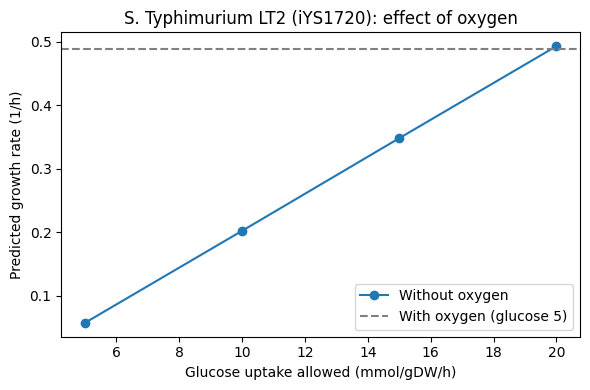

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. With oxygen (default medium, glucose 5)
aerobic_growth = model.slim_optimize()

# 2. Without oxygen, glucose 5 to 20
rows = []
with model:
    model.reactions.EX_o2_e.lower_bound = 0
    for glucose in [5, 10, 15, 20]:
        model.reactions.EX_glc__D_e.lower_bound = -glucose
        rows.append({"glucose": glucose,
                     "growth_no_oxygen": round(model.slim_optimize(), 3)})

results = pd.DataFrame(rows)
print("With oxygen (glucose 5):", round(aerobic_growth, 3))
print(results)

# 3. Save the numbers
results.to_csv("sim1_oxygen_results.csv", index=False)

# 4. Make the figure
plt.figure(figsize=(6, 4))
plt.plot(results["glucose"], results["growth_no_oxygen"], marker="o",
         label="Without oxygen")
plt.axhline(aerobic_growth, linestyle="--", color="gray",
            label="With oxygen (glucose 5)")
plt.xlabel("Glucose uptake allowed (mmol/gDW/h)")
plt.ylabel("Predicted growth rate (1/h)")
plt.title("S. Typhimurium LT2 (iYS1720): effect of oxygen")
plt.legend()
plt.tight_layout()
plt.savefig("fig_sim1_oxygen.png", dpi=200)
plt.show()

In [8]:
%pip install matplotlib


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
with model:
    model.reactions.EX_o2_e.lower_bound = 0
    for glucose in [5, 10, 15, 20]:
        model.reactions.EX_glc__D_e.lower_bound = -glucose
        print("Glucose", glucose, "→ growth", round(model.slim_optimize(), 3))

Glucose 5 → growth 0.057
Glucose 10 → growth 0.202
Glucose 15 → growth 0.348
Glucose 20 → growth 0.493


In [6]:
with model:
    model.reactions.EX_o2_e.lower_bound = 0
    growth_no_oxygen = model.slim_optimize()

print("With oxygen:   ", round(growth, 3))
print("Without oxygen:", round(growth_no_oxygen, 3))

With oxygen:    0.488
Without oxygen: 0.057


In [5]:
for reaction_id, limit in model.medium.items():
    print(reaction_id, limit)

EX_cobalt2_e 1000.0
EX_ca2_e 1000.0
EX_cbl1_e 0.01
EX_cl_e 1000.0
EX_h2o_e 100.0
EX_h_e 100.0
EX_k_e 1000.0
EX_mg2_e 1000.0
EX_mn2_e 1000.0
EX_mobd_e 1000.0
EX_na1_e 1000.0
EX_nh4_e 1000.0
EX_o2_e 18.5
EX_23dhb_e 1.427e-05
EX_co2_e 1000.0
EX_cu2_e 1000.0
EX_fe2_e 1000.0
EX_fe3_e 1000.0
EX_glc__D_e 5.0
EX_pi_e 1000.0
EX_so4_e 1000.0
EX_tungs_e 1000.0
EX_zn2_e 1000.0


In [4]:
growth = model.slim_optimize()
print("Predicted growth rate:", round(growth, 3), "per hour")

Predicted growth rate: 0.488 per hour


In [3]:
import httpx
from cobra.io import load_json_model

# Download the model file once (from the new https address)
url = "https://bigg.ucsd.edu/static/models/iYS1720.json"
response = httpx.get(url, follow_redirects=True, timeout=120)
response.raise_for_status()
with open("iYS1720.json", "wb") as f:
    f.write(response.content)

# Load it from your computer
model = load_json_model("iYS1720.json")
print("Reactions:", len(model.reactions))
print("Genes:", len(model.genes))

Reactions: 3357
Genes: 1707
